In [1]:
import torch

from chronos import ChronosPipeline

print("torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

torch: 2.14.0+xpu
CUDA available: False


In [2]:
from chronos import ChronosPipeline

pipeline = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-base",
    device_map="xpu",
    torch_dtype=torch.bfloat16,
)

config.json:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

c:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\.venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\dbsgh\.cache\huggingface\hub\models--amazon--chronos-t5-base. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
c:\Users\dbsgh\Desktop\Lab\chro

model.safetensors: reconstructing file:   0%|          |  0.00B /  806MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/257 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/142 [00:00<?, ?B/s]

In [3]:
print(type(pipeline))
print(next(pipeline.model.model.parameters()).device)
print(next(pipeline.model.model.parameters()).dtype)

<class 'chronos.chronos.ChronosPipeline'>
xpu:0
torch.bfloat16


In [4]:
from pathlib import Path
import numpy as np
from scipy.io import loadmat

PROJECT_ROOT = Path("..").resolve()

mat = loadmat(
    PROJECT_ROOT / "data" / "raw" / "B0005.mat",
    simplify_cells=True
)

cycles = mat["B0005"]["cycle"]

capacities = np.array([
    cycle["data"]["Capacity"]
    for cycle in cycles
    if cycle["type"] == "discharge"
], dtype=float)

soh_0005 = capacities / capacities[0]

context = torch.tensor(
    soh_0005[:64],
    dtype=torch.float32
)

print(context.shape)
print(context[:5])
print(context[-5:])

torch.Size([64])
tensor([1.0000, 0.9945, 0.9886, 0.9886, 0.9882])
tensor([0.9128, 0.9076, 0.9020, 0.9020, 0.8962])


In [5]:
forecast = pipeline.predict(
    context,
    prediction_length=16,
    num_samples=20
)

print("forecast shape:", forecast.shape)

forecast shape: torch.Size([1, 20, 16])


In [6]:
# 20개 sample의 horizon별 median
median_pred = forecast.median(dim=1).values[0].cpu().numpy()

# 실제 future SOH: cycle 65 ~ 80
y_true = soh_0005[64:80]

rmse = np.sqrt(np.mean((y_true - median_pred) ** 2))
mae = np.mean(np.abs(y_true - median_pred))

print("prediction shape:", median_pred.shape)
print()
print("True:")
print(np.round(y_true, 4))
print()
print("Chronos median:")
print(np.round(median_pred, 4))
print()
print(f"RMSE: {rmse:.6f}")
print(f"MAE : {mae:.6f}")

prediction shape: (16,)

True:
[0.8936 0.8909 0.8848 0.8822 0.8795 0.8768 0.8738 0.8679 0.8654 0.8627
 0.8567 0.8542 0.8537 0.8594 0.8482 0.8429]

Chronos median:
[0.8886 0.8886 0.8815 0.8815 0.8815 0.8745 0.8745 0.8674 0.8674 0.8674
 0.8604 0.8533 0.8604 0.8533 0.8463 0.8392]

RMSE: 0.003473
MAE : 0.002923


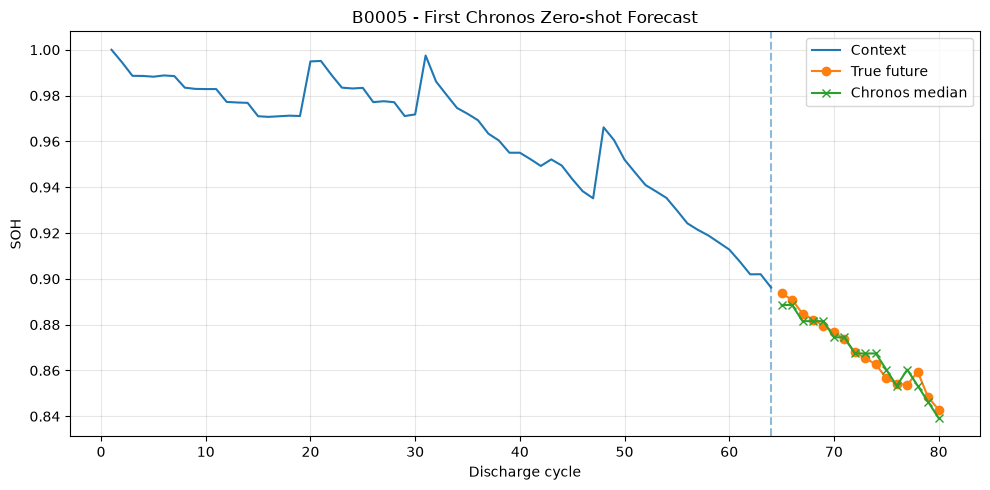

In [7]:
import matplotlib.pyplot as plt

context_x = np.arange(1, 65)
future_x = np.arange(65, 81)

plt.figure(figsize=(10, 5))

plt.plot(
    context_x,
    soh_0005[:64],
    label="Context"
)

plt.plot(
    future_x,
    y_true,
    marker="o",
    label="True future"
)

plt.plot(
    future_x,
    median_pred,
    marker="x",
    label="Chronos median"
)

plt.axvline(64, linestyle="--", alpha=0.5)

plt.xlabel("Discharge cycle")
plt.ylabel("SOH")
plt.title("B0005 - First Chronos Zero-shot Forecast")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
CONTEXT_LENGTH = 64
PREDICTION_LENGTH = 16

def make_windows(series, context_length=64, prediction_length=16):
    X = []
    y = []

    total_length = context_length + prediction_length

    for start in range(len(series) - total_length + 1):
        X.append(series[start:start + context_length])
        y.append(series[start + context_length:start + total_length])

    return np.array(X), np.array(y)

X_0005, y_0005 = make_windows(
    soh_0005,
    CONTEXT_LENGTH,
    PREDICTION_LENGTH
)

print(X_0005.shape, y_0005.shape)

(89, 64) (89, 16)


In [9]:
BATCH_SIZE = 16
NUM_SAMPLES = 20

torch.manual_seed(42)

all_preds = []

for start in range(0, len(X_0005), BATCH_SIZE):
    end = start + BATCH_SIZE

    context_batch = torch.tensor(
        X_0005[start:end],
        dtype=torch.float32
    )

    forecast_batch = pipeline.predict(
        context_batch,
        prediction_length=PREDICTION_LENGTH,
        num_samples=NUM_SAMPLES
    )

    median_batch = (
        forecast_batch
        .median(dim=1)
        .values
        .cpu()
        .numpy()
    )

    all_preds.append(median_batch)

    print(f"{min(end, len(X_0005))}/{len(X_0005)} done")

chronos_pred_0005 = np.concatenate(all_preds, axis=0)

print("prediction shape:", chronos_pred_0005.shape)

16/89 done
32/89 done
48/89 done
64/89 done
80/89 done
89/89 done
prediction shape: (89, 16)


In [10]:
chronos_rmse_0005 = np.sqrt(
    np.mean((y_0005 - chronos_pred_0005) ** 2)
)

chronos_mae_0005 = np.mean(
    np.abs(y_0005 - chronos_pred_0005)
)

print(f"B0005 Chronos RMSE: {chronos_rmse_0005:.6f}")
print(f"B0005 Chronos MAE : {chronos_mae_0005:.6f}")

B0005 Chronos RMSE: 0.013641
B0005 Chronos MAE : 0.009533


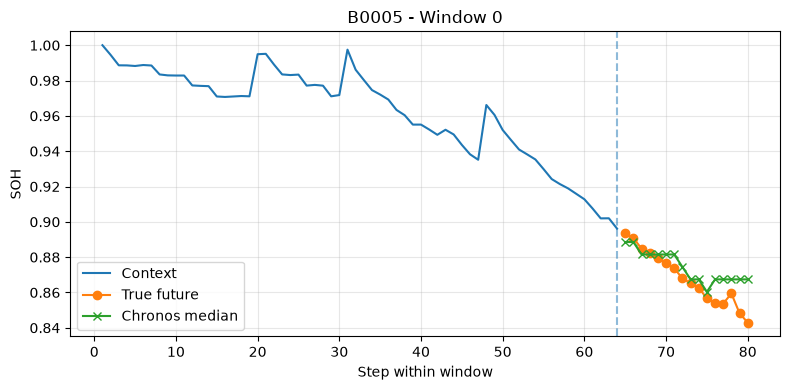

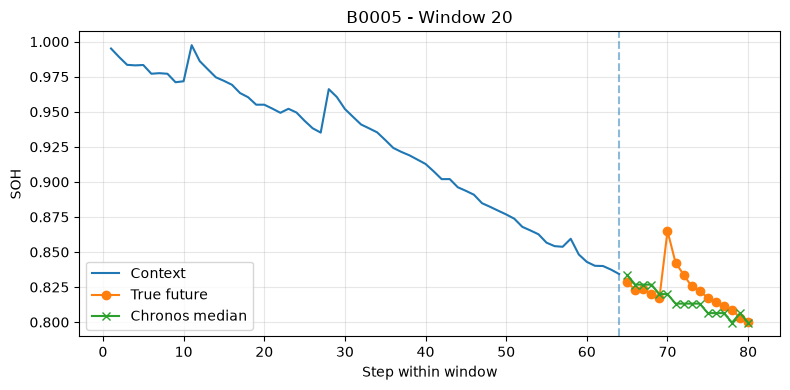

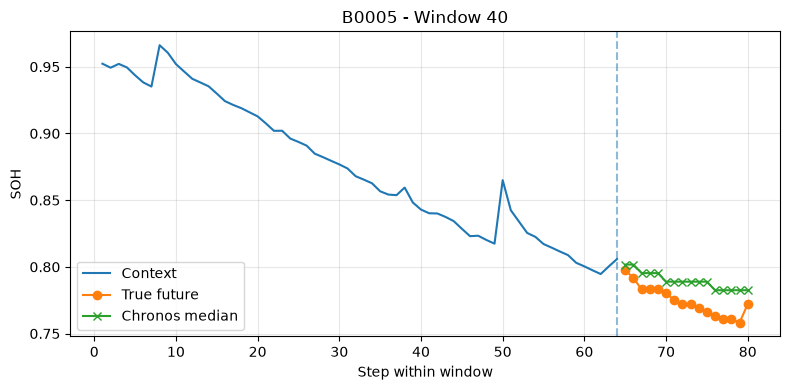

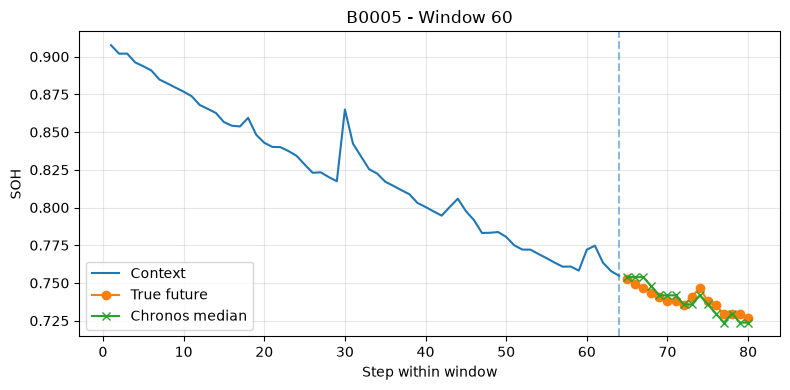

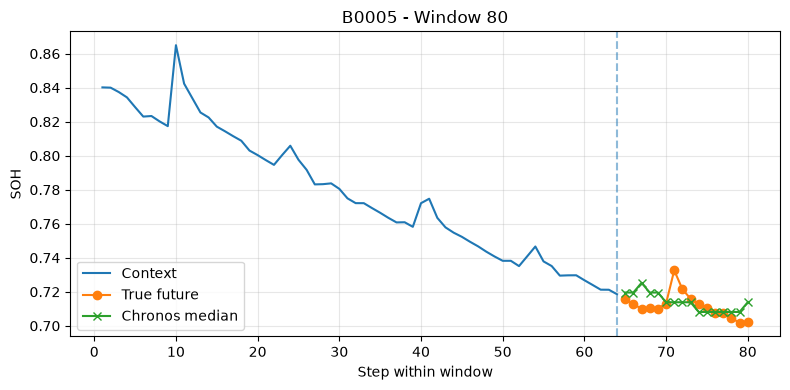

In [11]:
import matplotlib.pyplot as plt
import numpy as np

window_indices = [0, 20, 40, 60, 80]

for idx in window_indices:
    context = X_0005[idx]
    y_true = y_0005[idx]
    y_pred = chronos_pred_0005[idx]

    x_context = np.arange(1, len(context) + 1)
    x_future = np.arange(len(context) + 1, len(context) + len(y_true) + 1)

    plt.figure(figsize=(8, 4))
    plt.plot(x_context, context, label="Context")
    plt.plot(x_future, y_true, marker="o", label="True future")
    plt.plot(x_future, y_pred, marker="x", label="Chronos median")
    plt.axvline(len(context), linestyle="--", alpha=0.5)

    plt.title(f"B0005 - Window {idx}")
    plt.xlabel("Step within window")
    plt.ylabel("SOH")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [12]:
horizon_rmse = np.sqrt(
    np.mean((y_0005 - chronos_pred_0005) ** 2, axis=0)
)

horizon_mae = np.mean(
    np.abs(y_0005 - chronos_pred_0005),
    axis=0
)

for h in range(PREDICTION_LENGTH):
    print(
        f"h={h+1:2d}: "
        f"RMSE={horizon_rmse[h]:.6f}, "
        f"MAE={horizon_mae[h]:.6f}"
    )

h= 1: RMSE=0.008218, MAE=0.004616
h= 2: RMSE=0.010184, MAE=0.006032
h= 3: RMSE=0.011287, MAE=0.007324
h= 4: RMSE=0.012278, MAE=0.008160
h= 5: RMSE=0.012678, MAE=0.008568
h= 6: RMSE=0.012498, MAE=0.009153
h= 7: RMSE=0.013219, MAE=0.010120
h= 8: RMSE=0.013612, MAE=0.010435
h= 9: RMSE=0.014269, MAE=0.009864
h=10: RMSE=0.014060, MAE=0.010310
h=11: RMSE=0.014403, MAE=0.010727
h=12: RMSE=0.013867, MAE=0.010332
h=13: RMSE=0.014126, MAE=0.010530
h=14: RMSE=0.015831, MAE=0.011327
h=15: RMSE=0.016700, MAE=0.012061
h=16: RMSE=0.017917, MAE=0.012970


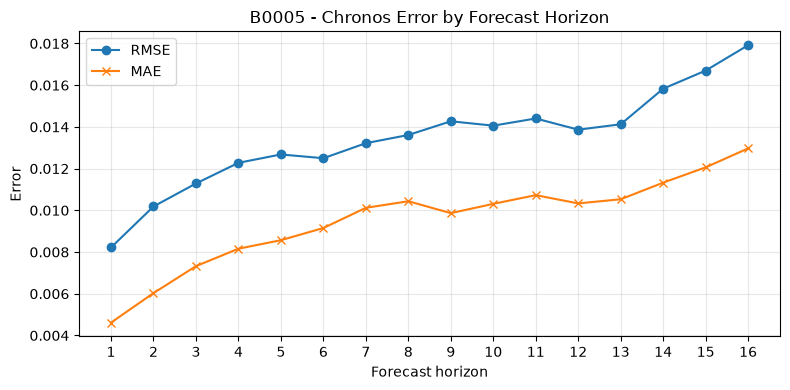

In [13]:
horizons = np.arange(1, PREDICTION_LENGTH + 1)

plt.figure(figsize=(8, 4))

plt.plot(
    horizons,
    horizon_rmse,
    marker="o",
    label="RMSE"
)

plt.plot(
    horizons,
    horizon_mae,
    marker="x",
    label="MAE"
)

plt.xlabel("Forecast horizon")
plt.ylabel("Error")
plt.title("B0005 - Chronos Error by Forecast Horizon")
plt.xticks(horizons)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [17]:
battery_ids = ["B0005", "B0006", "B0007", "B0018"]

soh_data = {}

for battery_id in battery_ids:
    mat = loadmat(
        PROJECT_ROOT / "data" / "raw" / f"{battery_id}.mat",
        simplify_cells=True
    )

    cycles = mat[battery_id]["cycle"]

    capacities = np.array([
        cycle["data"]["Capacity"]
        for cycle in cycles
        if cycle["type"] == "discharge"
    ], dtype=float)

    soh_data[battery_id] = capacities / capacities[0]

    print(
        battery_id,
        "cycles:",
        len(soh_data[battery_id])
    )

chronos_results = {
    "B0005": {
        "rmse": 0.013641,
        "mae": 0.009533
    }
}

B0005 cycles: 168
B0006 cycles: 168
B0007 cycles: 168
B0018 cycles: 132


In [18]:
remaining_ids = ["B0006", "B0007", "B0018"]

for battery_id in remaining_ids:
    X, y = make_windows(
        soh_data[battery_id],
        CONTEXT_LENGTH,
        PREDICTION_LENGTH
    )

    all_preds = []

    torch.manual_seed(42)

    for start in range(0, len(X), BATCH_SIZE):
        context_batch = torch.tensor(
            X[start:start + BATCH_SIZE],
            dtype=torch.float32
        )

        forecast_batch = pipeline.predict(
            context_batch,
            prediction_length=PREDICTION_LENGTH,
            num_samples=NUM_SAMPLES
        )

        median_batch = (
            forecast_batch
            .median(dim=1)
            .values
            .cpu()
            .numpy()
        )

        all_preds.append(median_batch)

    y_pred = np.concatenate(all_preds, axis=0)

    battery_rmse = np.sqrt(np.mean((y - y_pred) ** 2))
    battery_mae = np.mean(np.abs(y - y_pred))

    chronos_results[battery_id] = {
        "rmse": battery_rmse,
        "mae": battery_mae
    }

    print(
        f"{battery_id}: "
        f"RMSE={battery_rmse:.6f}, "
        f"MAE={battery_mae:.6f}"
    )

B0006: RMSE=0.019418, MAE=0.013335
B0007: RMSE=0.012504, MAE=0.008332
B0018: RMSE=0.023311, MAE=0.017199
